# Week 11 — 0: setup

SAFE BY DEFAULT. Run All loads saved real results if present; otherwise it uses fabricated smoke fixtures (H/I read saved results only). No datasets/models are downloaded automatically. QASPER TEST is blocked.

For a user full run: set `RUN_FULL=True` and `RUN_SMOKE=False` in the next cell. Every later setup is derived automatically. Existing validated rows are reused. `OVERWRITE=True` is deliberately unsupported.

Before full setup, prepare HotpotQA/SciFact once with `sara_env/bin/python scripts/week11/prepare_datasets.py --download`. Decide the fixed sample size (default 50 questions per dataset) and LLMLingua qualification before freezing this setup.


In [1]:
RUN_SMOKE = False
RUN_FULL = True
RESUME = True
OVERWRITE = False
RUN_SETUP_SMOKE = RUN_SMOKE
RUN_0_FULL = RUN_FULL
BUILD_FULL_CACHES = RUN_FULL
SMOKE_LIMIT = 3
REVIEW_PHASE = None
REVIEWED_CONFIG = None
REVIEW_REASON = None


In [2]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
while not (ROOT/'src/week11').is_dir():
    if ROOT == ROOT.parent: raise FileNotFoundError('Open inside CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.week11.protocol import load, review
from src.week11.runner import execute, notebook_smoke
from src.week11.dashboard import status, resources
cfg = load()
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 70)
configuration_df = pd.DataFrame([{'setting': k, 'value': str(v)} for k,v in cfg.items()])
display(configuration_df)
run_status_df = status(cfg)
display(run_status_df)
display(resources(cfg))


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,setting,value
0,version,v1
1,output_root,results/week11/multigranular/v1
2,cache_root,cache/week11/v1
3,verification_dataset,SciFact
4,primary_reader,Qwen
5,seed,42
6,epsilon,0.01
7,bootstrap_resamples,10000
8,characterization_queries_per_dataset,50
9,query_sampling,"sha256(dataset,query_id,seed), independent of labels"


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False


,phase,dataset,configured_queries,planned_configurations,executable_configurations,pending_configurations,answer_rows_upper_bound,executable_answer_rows_upper_bound,new_lm_calls,actual_time_estimate
0,0,QASPER,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
1,0,HotpotQA,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
2,0,SciFact,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
3,A,QASPER,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
4,A,HotpotQA,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
5,A,SciFact,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
6,B,QASPER,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
7,B,HotpotQA,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
8,B,SciFact,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
9,C,QASPER,50,41,37,4,2050,1850,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured


## Execute or resume

Synthetic output is stored only under `smoke/`. Pending token-compressor conditions are reported explicitly, never filled with invented scores. Full dependent phases require the previous manual freeze.

In [3]:
if OVERWRITE: raise ValueError('Immutable results: use a new output version instead of overwrite')
if not RESUME: raise ValueError('Resume stays enabled; new experiments require a new configured version')
effective_smoke = notebook_smoke(cfg, '0', RUN_SMOKE, RUN_FULL)
frames, figures = execute('0', cfg, full=RUN_FULL, explicit=RUN_FULL, smoke=effective_smoke, limit=SMOKE_LIMIT)
print('SYNTHETIC SMOKE ONLY' if effective_smoke else 'Saved/full result tables; inspect status before review')
display(frames.get('condition_status_df', pd.DataFrame()))


Saved/full result tables; inspect status before review


""


### dataset_summary_df

In [4]:
dataset_summary_df = frames.get('dataset_summary_df', pd.DataFrame())
display(dataset_summary_df)

,dataset,split,n_queries,candidate_corpus,synthetic,available_queries
0,HotpotQA,dev,50,provided ten distractor paragraphs,False,7405
1,QASPER,dev,50,complete matching scientific paper,False,231
2,SciFact,dev,50,all corpus abstracts; never only cited/gold documents,False,300


### answer_type_df

In [5]:
answer_type_df = frames.get('answer_type_df', pd.DataFrame())
display(answer_type_df)

,dataset,answer_type,count
0,HotpotQA,bridge,42
1,HotpotQA,comparison,8
2,QASPER,free_form,18
3,QASPER,yes_no,9
4,QASPER,extractive,23
5,SciFact,REFUTE,9
6,SciFact,NOT_ENOUGH_INFO,25
7,SciFact,SUPPORT,16


### document_length_df

In [6]:
document_length_df = frames.get('document_length_df', pd.DataFrame())
display(document_length_df)

,dataset,document_id,tokens
0,HotpotQA,5f67264f62a3eced7188b7ae,236
1,HotpotQA,e2a680741f3f5f33c3b11461,48
2,HotpotQA,9e2106709aa2e6e62e315dba,154
3,HotpotQA,756a4a3da81133d5de166466,97
4,HotpotQA,74e91332bf946463b8b39f98,204
...,...,...,...
5717,SciFact,195689316,826
5718,SciFact,195689757,224
5719,SciFact,196664003,323
5720,SciFact,198133135,443


### hierarchy_stats_df

In [7]:
hierarchy_stats_df = frames.get('hierarchy_stats_df', pd.DataFrame())
display(hierarchy_stats_df)

,dataset,document_id,unit_type,token_count,units_per_document
0,HotpotQA,5f67264f62a3eced7188b7ae,DOCUMENT,236,1
1,HotpotQA,5f67264f62a3eced7188b7ae,PASSAGE,236,1
2,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,8,8
3,HotpotQA,5f67264f62a3eced7188b7ae,PROPOSITION,8,8
4,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,15,8
...,...,...,...,...,...
136083,SciFact,198309074,PROPOSITION,26,12
136084,SciFact,198309074,SENTENCE,32,12
136085,SciFact,198309074,PROPOSITION,32,12
136086,SciFact,198309074,SENTENCE,38,12


### model_registry_df

In [8]:
model_registry_df = frames.get('model_registry_df', pd.DataFrame())
display(model_registry_df)

,model,id,revision,status,smoke_model_loaded,tokenizer,dtype,quantization,max_context,max_new_tokens,decoding,seed,peak_vram_measured
0,Mistral,mistralai/Mistral-7B-Instruct-v0.2,63a8b081895390a26e140280378bc85ec8bce07a,CACHED_SNAPSHOT,False,mistralai/Mistral-7B-Instruct-v0.2,float16,NaN,8192.0,128.0,greedy,42.0,NaN
1,MiniLM,sentence-transformers/all-MiniLM-L6-v2,1110a243fdf4706b3f48f1d95db1a4f5529b4d41,CACHED_SNAPSHOT,False,sentence-transformers/all-MiniLM-L6-v2,float32,NaN,NaN,NaN,NaN,42.0,NaN
2,SFR,Salesforce/SFR-Embedding-Mistral,33a60fe7b5e00b9414981280c571e8a4f9f42f1b,CACHED_SNAPSHOT,False,Salesforce/SFR-Embedding-Mistral,float16,NaN,NaN,NaN,NaN,42.0,NaN
3,Qwen,Qwen/Qwen3-8B,b968826d9c46dd6066d109eabc6255188de91218,CACHED_SNAPSHOT,False,Qwen/Qwen3-8B,float16,NaN,8192.0,128.0,greedy,42.0,NaN
4,Llama,meta-llama/Llama-3.1-8B-Instruct,0e9e39f249a16976918f6564b8830bc894c89659,CACHED_SNAPSHOT,False,meta-llama/Llama-3.1-8B-Instruct,float16,NaN,8192.0,128.0,greedy,42.0,NaN
5,LLMLingua-2,microsoft/llmlingua-2-xlm-roberta-large-meetingbank,NaN,PENDING_DEPENDENCY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### cache_status_df

In [9]:
cache_status_df = frames.get('cache_status_df', pd.DataFrame())
display(cache_status_df)

,namespace,path,files
0,datasets,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/datasets,5874
1,hierarchy,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/hiera...,5723
2,embeddings,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/embed...,554
3,index/bm25,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/index...,724
4,index/sfr,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/index...,451
5,index/minilm,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/index...,451
6,selections,/home/gunavenkat/Downloads/CS787-RAG-Project/cache/week11/v1/selec...,5551


## Figures and underlying tables

Each PNG/PDF has a source CSV. Different datasets are plotted separately; cross-dataset displays use ranks/counts.

document_length HotpotQA


,dataset,document_id,tokens
0,HotpotQA,5f67264f62a3eced7188b7ae,236
1,HotpotQA,e2a680741f3f5f33c3b11461,48
2,HotpotQA,9e2106709aa2e6e62e315dba,154
3,HotpotQA,756a4a3da81133d5de166466,97
4,HotpotQA,74e91332bf946463b8b39f98,204
...,...,...,...
494,HotpotQA,b3d2e173074b545c6c553558,105
495,HotpotQA,921ddf2e3045f26f545eea59,35
496,HotpotQA,40d382444f36d44eb1de6ec3,156
497,HotpotQA,fc6fd48629d515e0ec603984,145


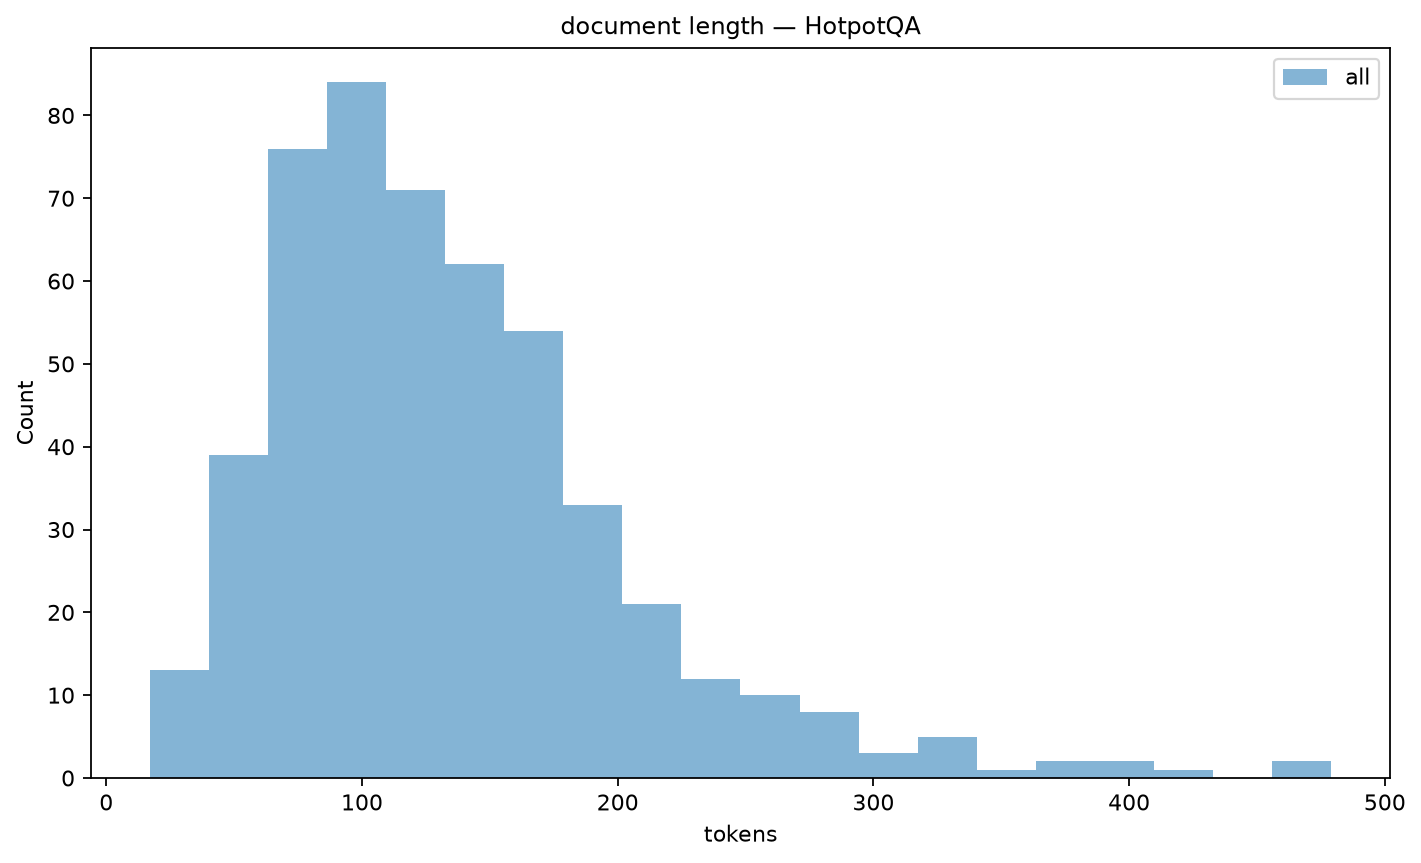

document_length QASPER


,dataset,document_id,tokens
0,QASPER,45,5398
1,QASPER,549,5507
2,QASPER,590,3529
3,QASPER,203,5568
4,QASPER,715,7723
5,QASPER,604,2334
6,QASPER,105,7262
7,QASPER,594,1072
8,QASPER,591,6225
9,QASPER,772,4049


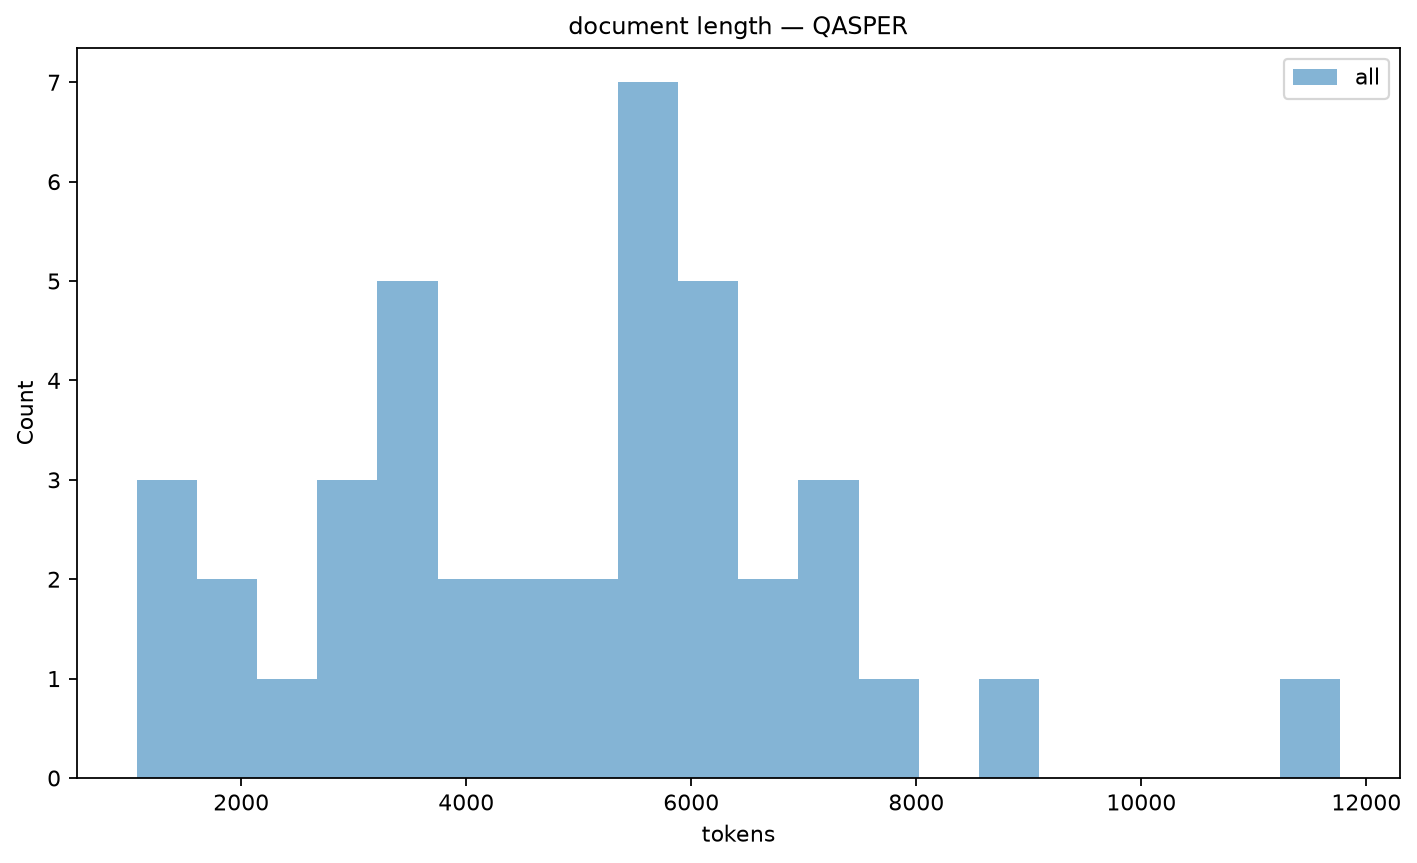

document_length SciFact


,dataset,document_id,tokens
0,SciFact,4983,454
1,SciFact,5836,372
2,SciFact,7912,257
3,SciFact,18670,381
4,SciFact,19238,372
...,...,...,...
5178,SciFact,195689316,826
5179,SciFact,195689757,224
5180,SciFact,196664003,323
5181,SciFact,198133135,443


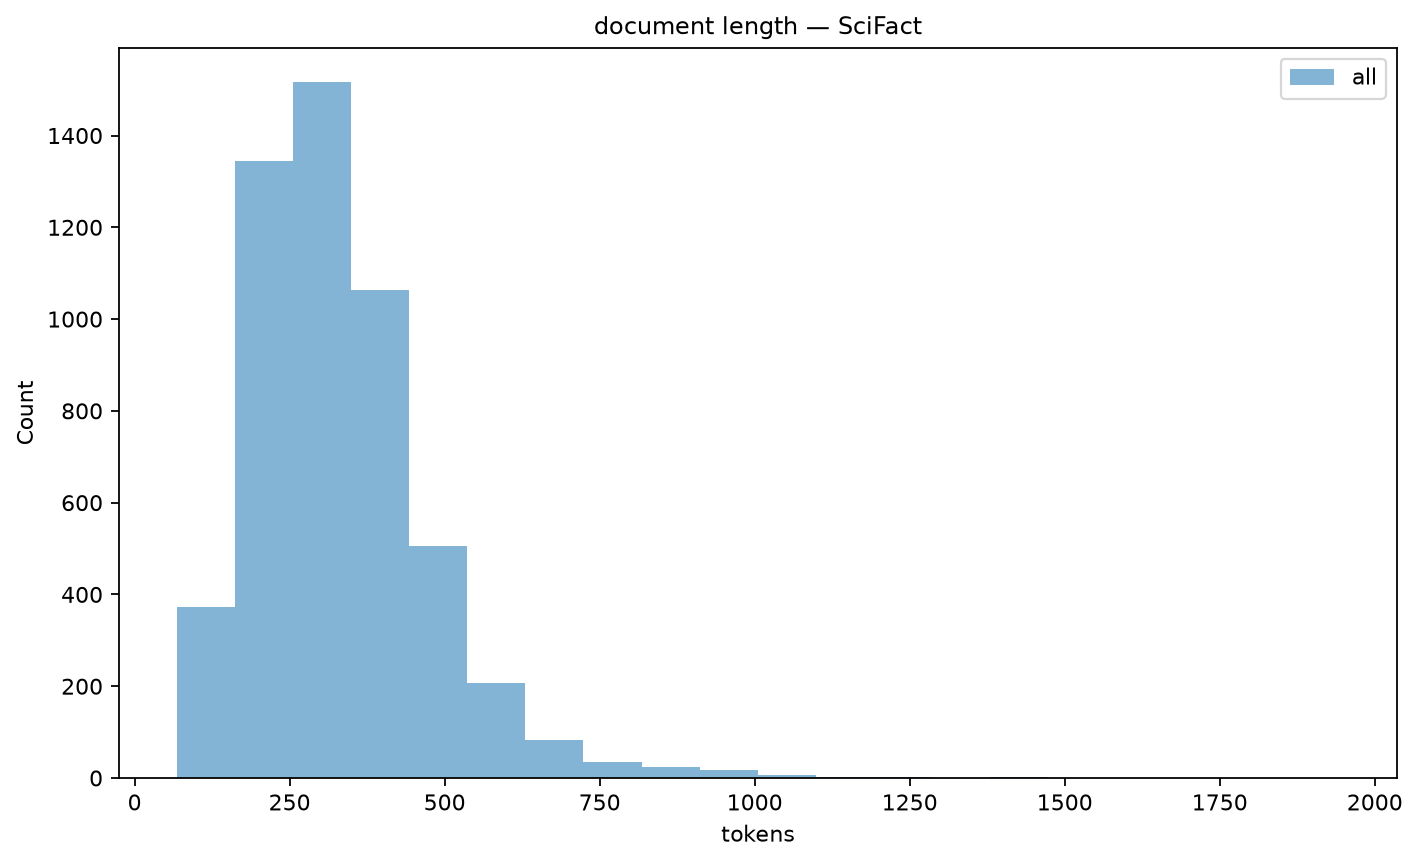

answer_types HotpotQA


,dataset,answer_type,count
0,HotpotQA,bridge,42
1,HotpotQA,comparison,8


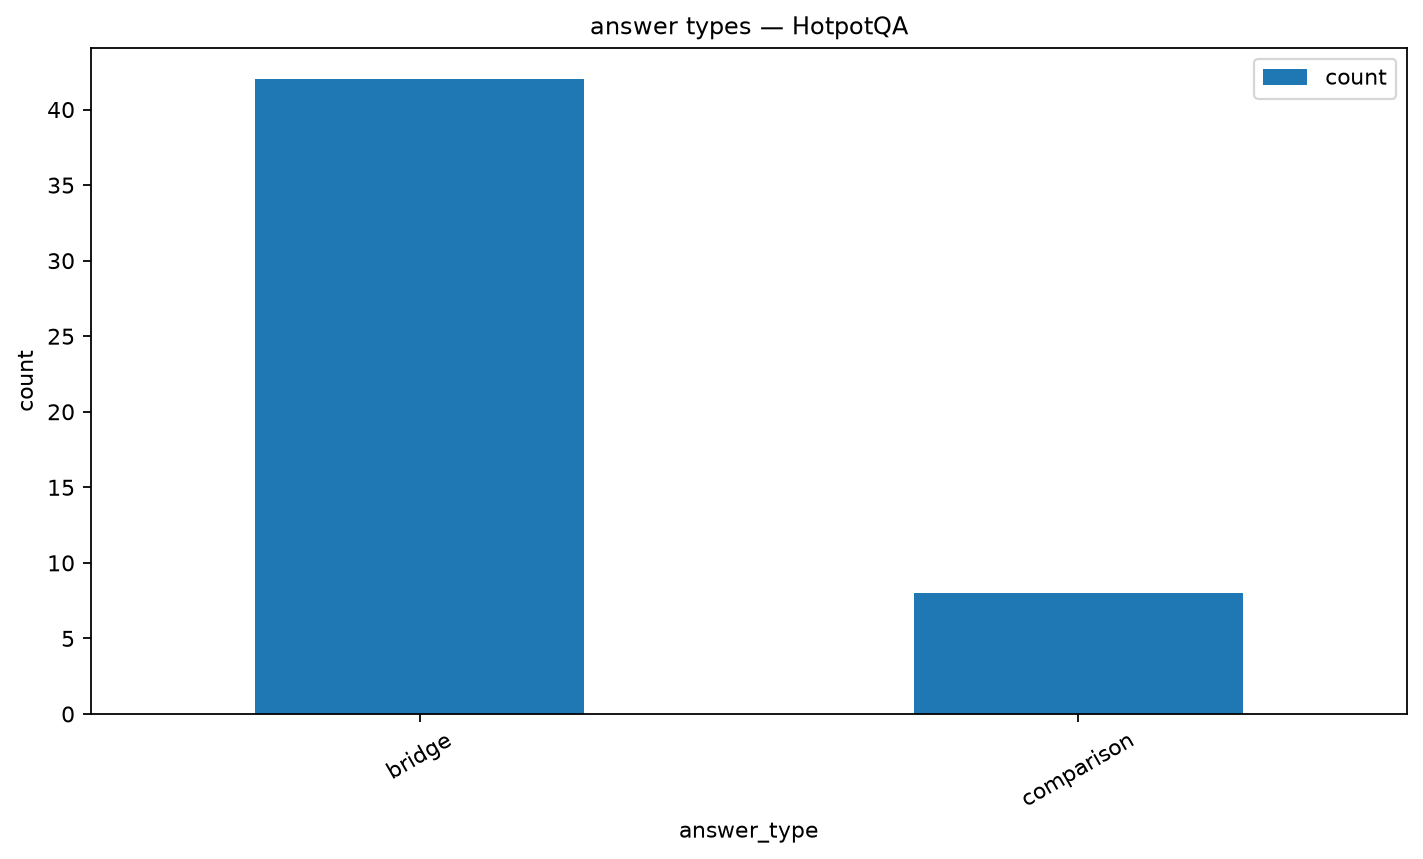

answer_types QASPER


,dataset,answer_type,count
0,QASPER,free_form,18
1,QASPER,yes_no,9
2,QASPER,extractive,23


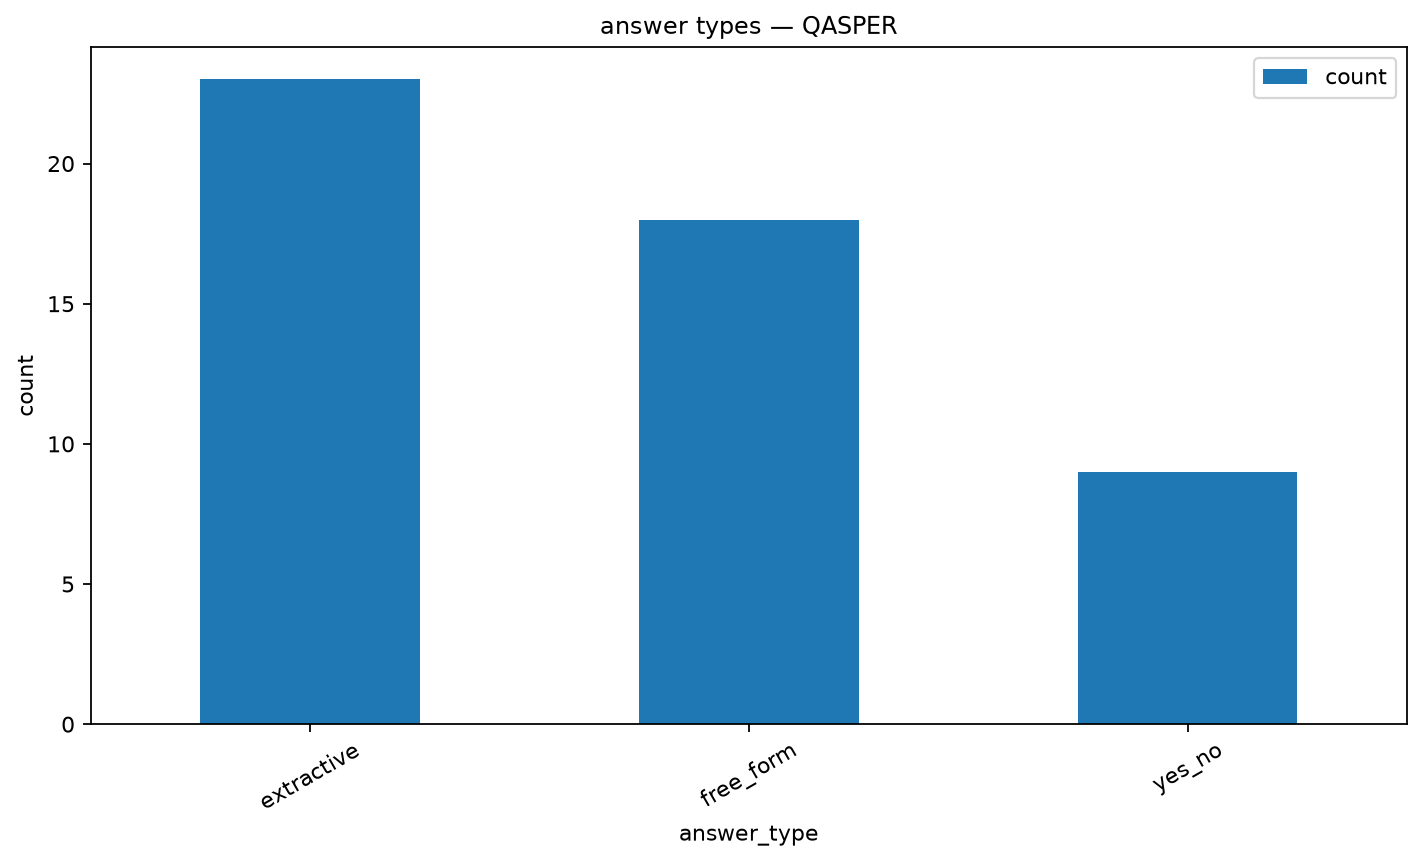

answer_types SciFact


,dataset,answer_type,count
0,SciFact,REFUTE,9
1,SciFact,NOT_ENOUGH_INFO,25
2,SciFact,SUPPORT,16


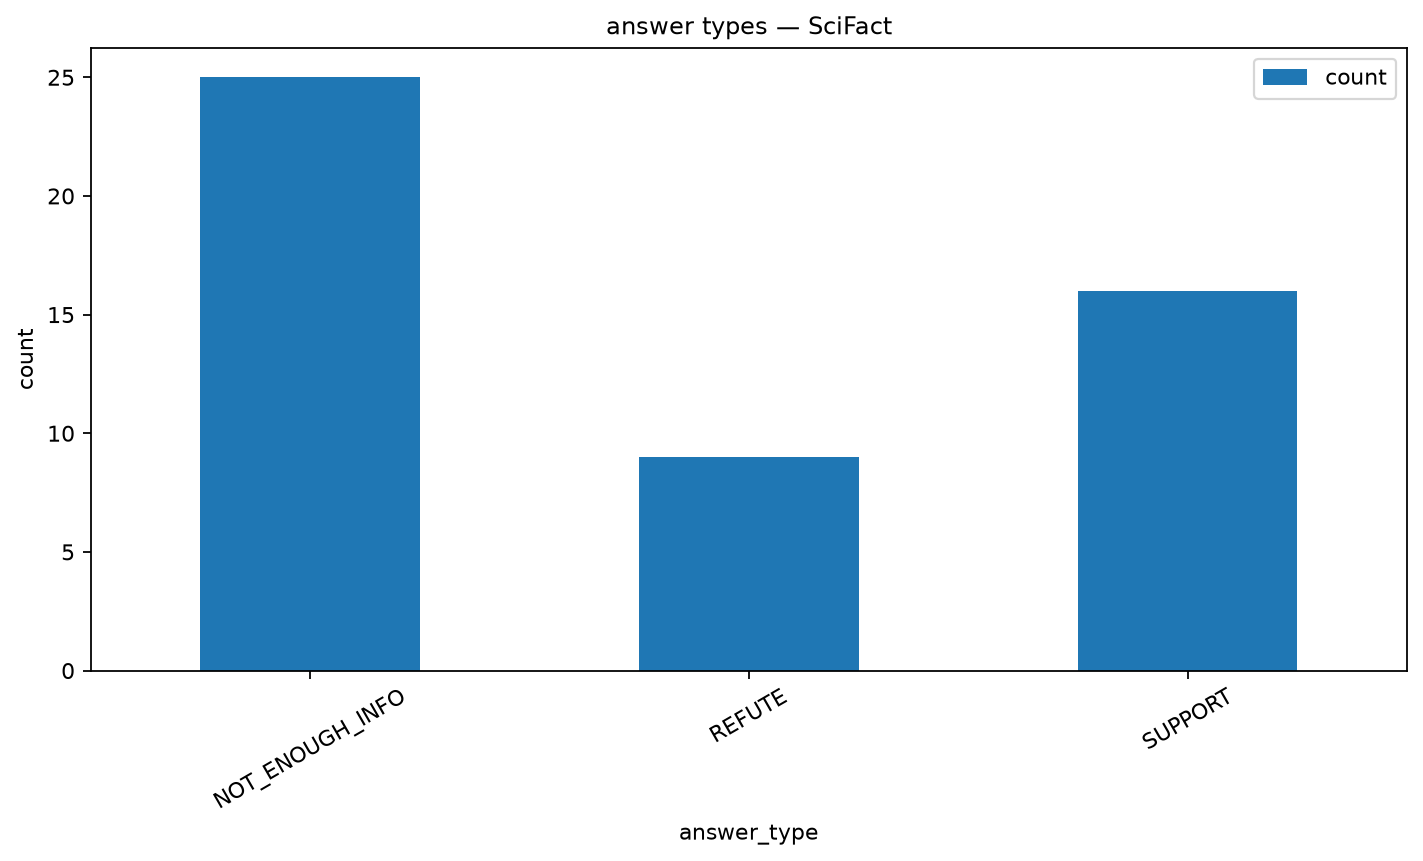

unit_lengths HotpotQA


,dataset,document_id,unit_type,token_count,units_per_document
0,HotpotQA,5f67264f62a3eced7188b7ae,DOCUMENT,236,1
1,HotpotQA,5f67264f62a3eced7188b7ae,PASSAGE,236,1
2,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,8,8
3,HotpotQA,5f67264f62a3eced7188b7ae,PROPOSITION,8,8
4,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,15,8
...,...,...,...,...,...
6207,HotpotQA,899d135ecdbfbd535102a2b4,PROPOSITION,26,5
6208,HotpotQA,899d135ecdbfbd535102a2b4,SENTENCE,27,5
6209,HotpotQA,899d135ecdbfbd535102a2b4,PROPOSITION,27,5
6210,HotpotQA,899d135ecdbfbd535102a2b4,SENTENCE,13,5


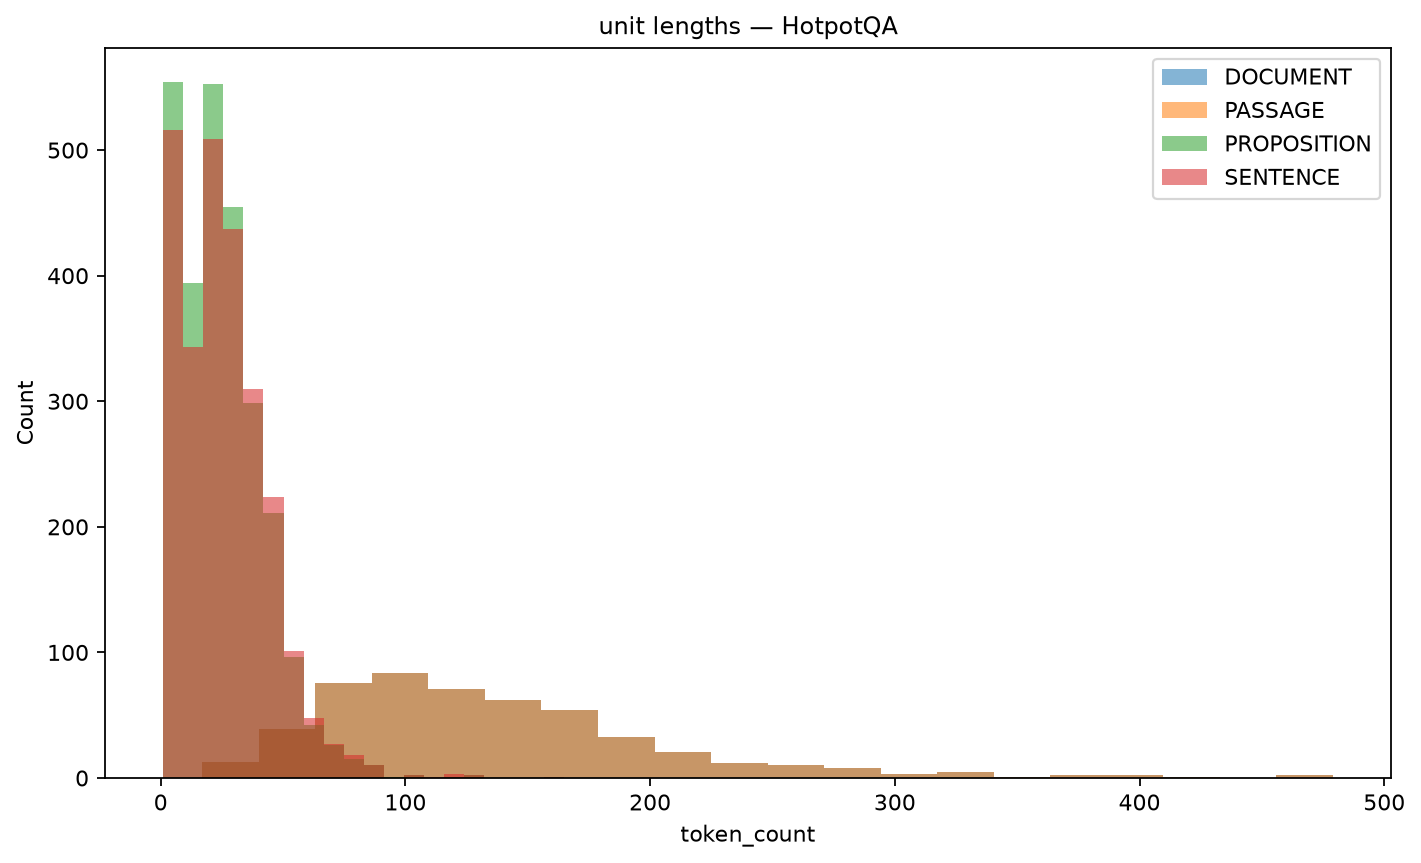

unit_lengths QASPER


,dataset,document_id,unit_type,token_count,units_per_document
0,QASPER,45,DOCUMENT,5398,1
1,QASPER,45,PASSAGE,256,22
2,QASPER,45,SENTENCE,46,213
3,QASPER,45,PROPOSITION,46,214
4,QASPER,45,SENTENCE,21,213
...,...,...,...,...,...
15171,QASPER,572,PASSAGE,42,47
15172,QASPER,572,SENTENCE,30,460
15173,QASPER,572,PROPOSITION,30,475
15174,QASPER,572,SENTENCE,12,460


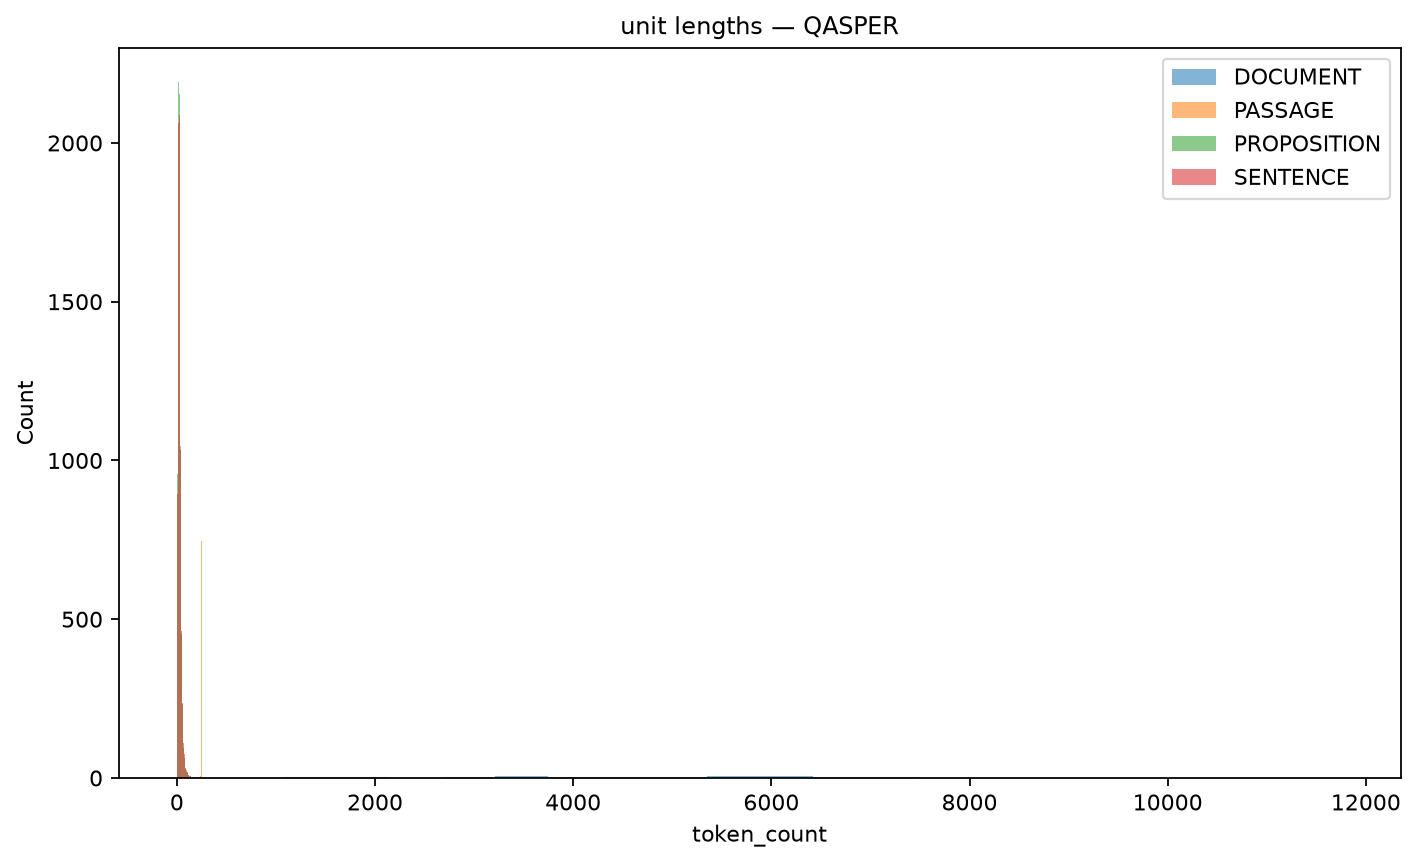

unit_lengths SciFact


,dataset,document_id,unit_type,token_count,units_per_document
0,SciFact,4983,DOCUMENT,454,1
1,SciFact,4983,PASSAGE,454,1
2,SciFact,4983,SENTENCE,19,15
3,SciFact,4983,PROPOSITION,19,17
4,SciFact,4983,SENTENCE,24,15
...,...,...,...,...,...
114695,SciFact,198309074,PROPOSITION,26,12
114696,SciFact,198309074,SENTENCE,32,12
114697,SciFact,198309074,PROPOSITION,32,12
114698,SciFact,198309074,SENTENCE,38,12


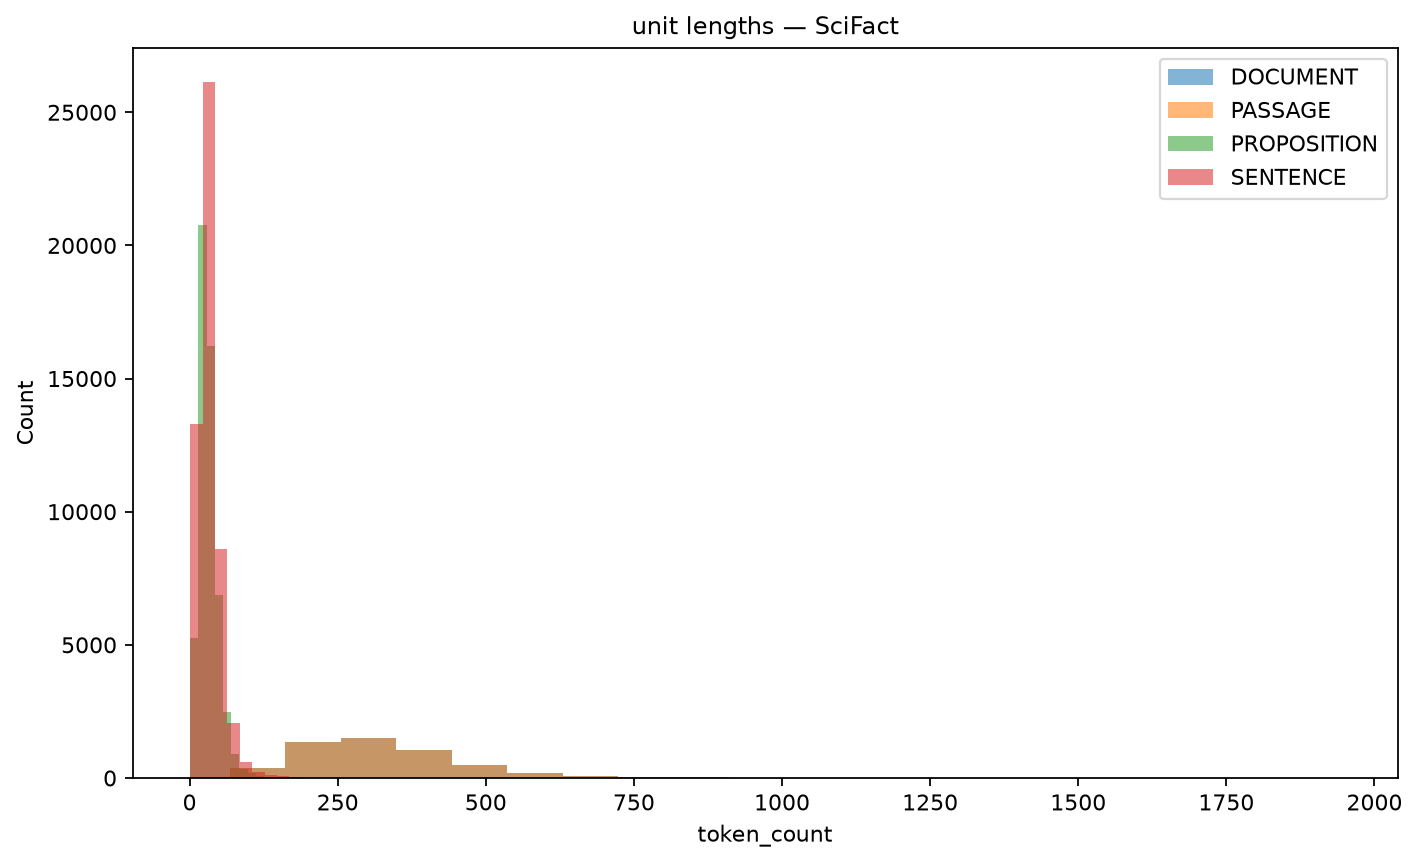

units_per_document HotpotQA


,dataset,document_id,unit_type,token_count,units_per_document
0,HotpotQA,5f67264f62a3eced7188b7ae,DOCUMENT,236,1
1,HotpotQA,5f67264f62a3eced7188b7ae,PASSAGE,236,1
2,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,8,8
3,HotpotQA,5f67264f62a3eced7188b7ae,PROPOSITION,8,8
4,HotpotQA,5f67264f62a3eced7188b7ae,SENTENCE,15,8
...,...,...,...,...,...
6207,HotpotQA,899d135ecdbfbd535102a2b4,PROPOSITION,26,5
6208,HotpotQA,899d135ecdbfbd535102a2b4,SENTENCE,27,5
6209,HotpotQA,899d135ecdbfbd535102a2b4,PROPOSITION,27,5
6210,HotpotQA,899d135ecdbfbd535102a2b4,SENTENCE,13,5


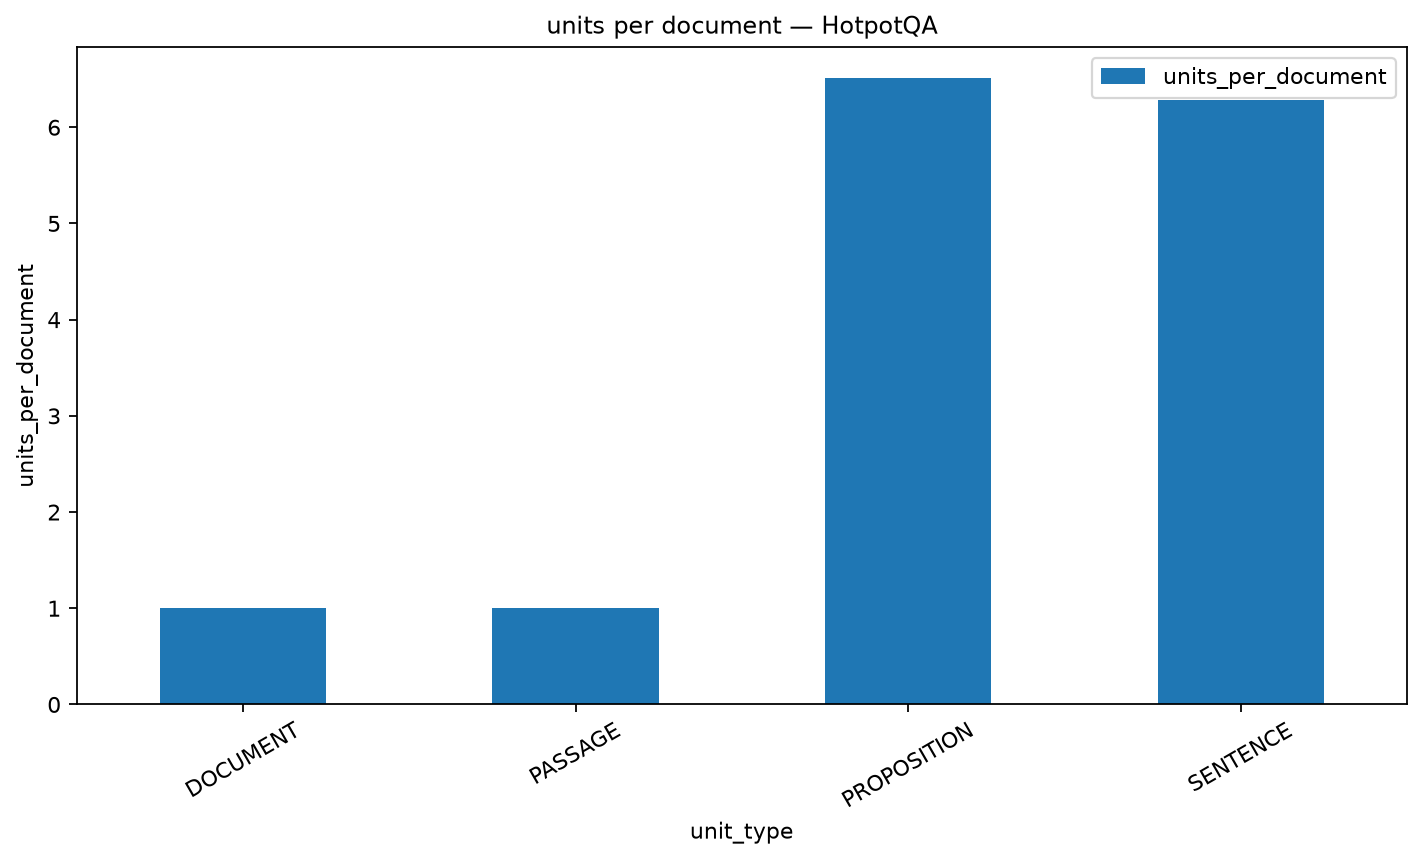

units_per_document QASPER


,dataset,document_id,unit_type,token_count,units_per_document
0,QASPER,45,DOCUMENT,5398,1
1,QASPER,45,PASSAGE,256,22
2,QASPER,45,SENTENCE,46,213
3,QASPER,45,PROPOSITION,46,214
4,QASPER,45,SENTENCE,21,213
...,...,...,...,...,...
15171,QASPER,572,PASSAGE,42,47
15172,QASPER,572,SENTENCE,30,460
15173,QASPER,572,PROPOSITION,30,475
15174,QASPER,572,SENTENCE,12,460


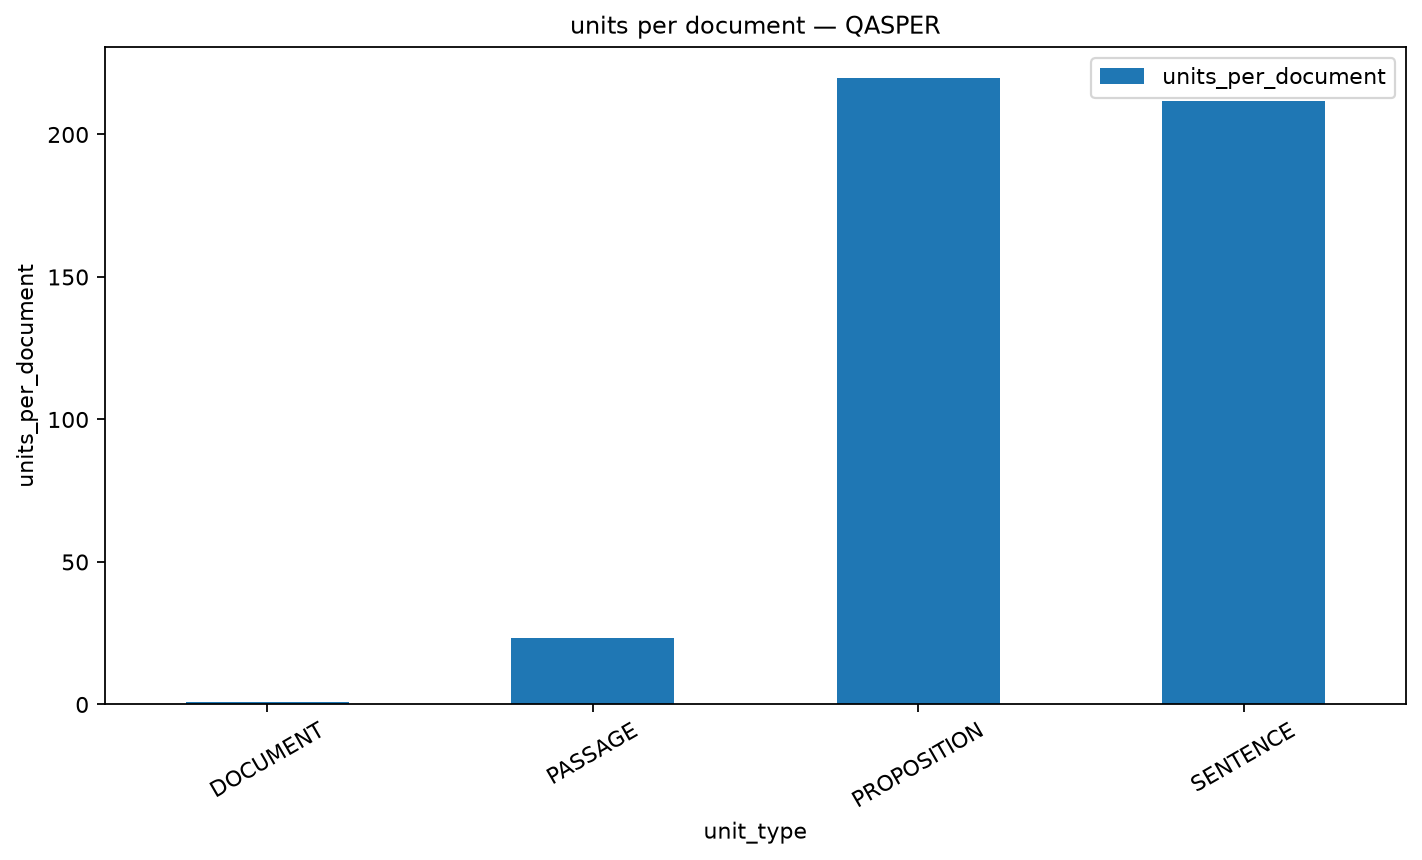

units_per_document SciFact


,dataset,document_id,unit_type,token_count,units_per_document
0,SciFact,4983,DOCUMENT,454,1
1,SciFact,4983,PASSAGE,454,1
2,SciFact,4983,SENTENCE,19,15
3,SciFact,4983,PROPOSITION,19,17
4,SciFact,4983,SENTENCE,24,15
...,...,...,...,...,...
114695,SciFact,198309074,PROPOSITION,26,12
114696,SciFact,198309074,SENTENCE,32,12
114697,SciFact,198309074,PROPOSITION,32,12
114698,SciFact,198309074,SENTENCE,38,12


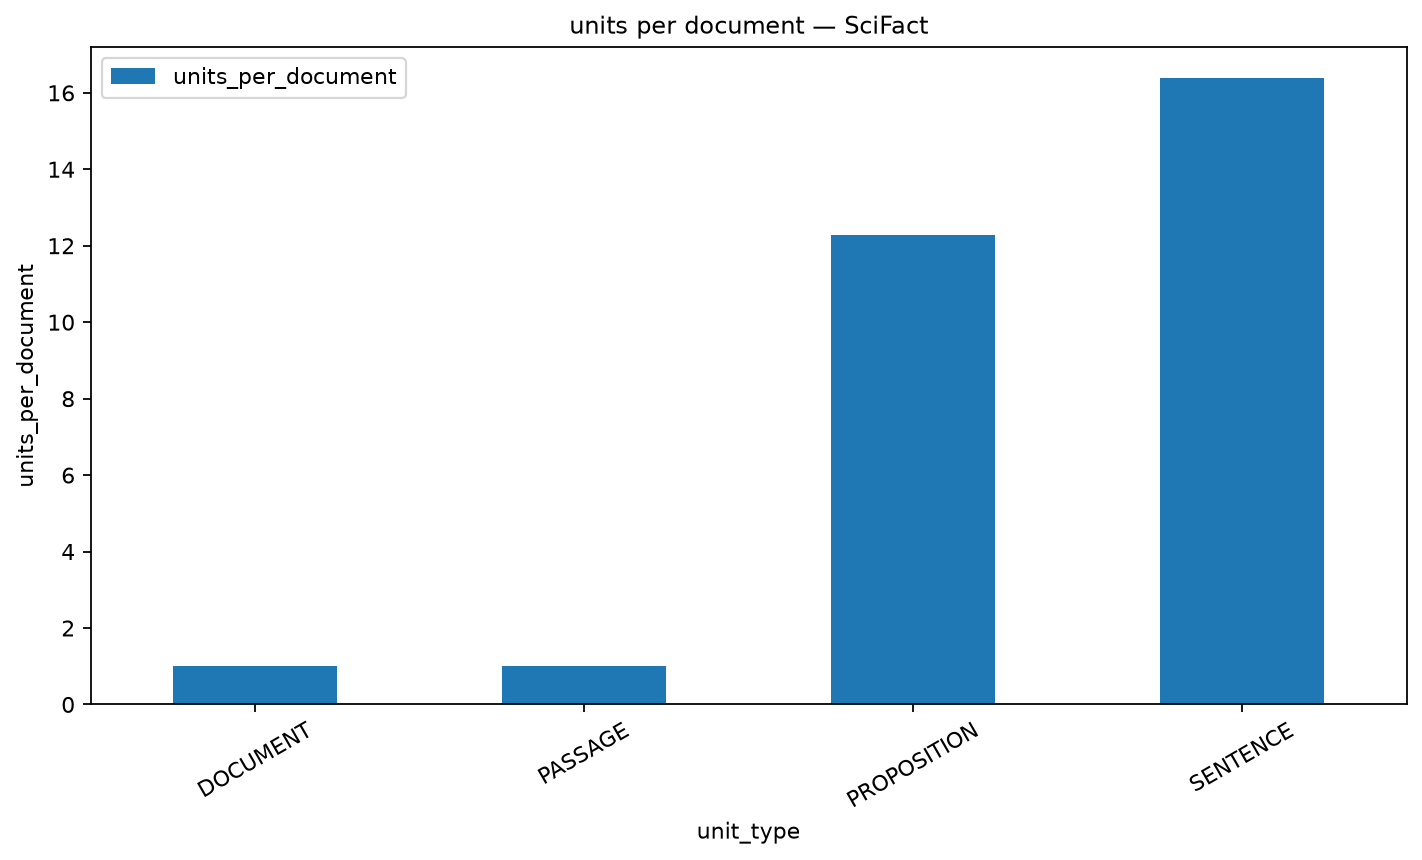

In [10]:
for figure in figures:
    print(figure['name'], figure['dataset'])
    display(pd.read_csv(figure['data']))
    display(Image(filename=figure['png']))
if not figures: print('No completed data for these plots yet; no fabricated values were substituted.')


## Manual review / freeze

After inspecting real completed results, edit the review fields in the first FLAGS cell. Set `REVIEW_PHASE` to this phase, `REVIEWED_CONFIG` to a dictionary, and give a rationale. No winning setting is chosen automatically. Smoke cannot be frozen. If optional conditions remain pending, list them explicitly in `REVIEWED_CONFIG["waive_pending"]`, or qualify them before running.

In [11]:
if REVIEW_PHASE is not None:
    if RUN_SMOKE: raise ValueError('Cannot freeze fabricated smoke output')
    if REVIEW_PHASE != '0': raise ValueError('Review this notebook phase only')
    display(review(cfg, REVIEW_PHASE, REVIEWED_CONFIG, REVIEW_REASON))
else:
    print('Review not requested. No downstream configuration was selected automatically.')
display(status(cfg))


Review not requested. No downstream configuration was selected automatically.


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
